<a href="https://colab.research.google.com/github/XomiDessu/Caso_1_PHA_Humano/blob/Integrante-4-EVo2/04_evo2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evo2: ΔlogP de las variantes

**Responsable:** Integrante 4  
**Proyecto:** Caso 1 · PAH (GRCh38, NM_000277.3, NP_000268.1, PDB 6HYC)


In [1]:
# Configuración: correr esta celda primero
import os
if not os.path.exists("Caso_1_PHA_Humano"):
    !git clone https://github.com/XomiDessu/Caso_1_PHA_Humano.git
%cd Caso_1_PHA_Humano
%pip install -q pandas numpy requests matplotlib biopython

import pandas as pd
import numpy as np


Cloning into 'Caso_1_PHA_Humano'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 69 (delta 20), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 116.72 KiB | 2.33 MiB/s, done.
Resolving deltas: 100% (20/20), done.
/content/Caso_1_PHA_Humano


In [2]:
from getpass import getpass
NVIDIA_API_KEY = "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"


## 1. API key con getpass() y endpoints


In [3]:
import os
import requests
from getpass import getpass

# Verificar API key (usa la que ya definiste arriba o la pide si reinicias)
if "NVIDIA_API_KEY" not in globals() or not NVIDIA_API_KEY:
    NVIDIA_API_KEY = os.getenv("NVCF_RUN_KEY") or getpass("Pega tu NVIDIA API key: ")

# Endpoints de NVIDIA NIM para Evo2 y Ensembl REST API
EVO2_40B_URL = "https://health.api.nvidia.com/v1/biology/arc/evo2-40b/forward"
EVO2_7B_URL = "https://health.api.nvidia.com/v1/biology/arc/evo2-7b/forward"
ENSEMBL_URL = "https://rest.ensembl.org"

# Encabezados de autenticación para NVIDIA
HEADERS_NVIDIA = {
    "Authorization": f"Bearer {NVIDIA_API_KEY}",
    "Content-Type": "application/json",
    "Accept": "application/json"
}

print("✅ Endpoints y headers configurados correctamente.")

✅ Endpoints y headers configurados correctamente.


## 2. Función para descargar la ventana de ADN desde Ensembl


In [4]:
import requests

def obtener_secuencia_ensembl(cromosoma, inicio, fin):
    """
    Descarga una secuencia de ADN específica usando la API REST de Ensembl.
    """
    # Ensembl usa el servidor que ya definimos o directamente su URL
    url = f"https://rest.ensembl.org/sequence/region/human/{cromosoma}:{inicio}..{fin}:1"

    headers = {"Content-Type": "text/plain"}

    response = requests.get(url, headers=headers)

    if response.status_code == 200:
        return response.text
    else:
        print(f"Error al descargar (Código {response.status_code}): {response.text}")
        return None

# Prueba de que la función trabaja correctamente (Fragmento del cromosoma 12 - gen PAH)
secuencia_prueba = obtener_secuencia_ensembl("12", 102834000, 102834050)
print("✅ Secuencia descargada con éxito:")
print(secuencia_prueba)

✅ Secuencia descargada con éxito:
AAAAATTAGCCAGGAGTCATGTCACATACCAGCTACTTGGGTAGCTGAAGC


## 3. Función puntuar_variante: ΔlogP en el sitio y en la ventana, ambas hebras


In [9]:
import numpy as np
import requests
import json
import base64
import io
import time

def rev_comp(seq):
    """Retorna el reverso complementario de una secuencia de ADN."""
    comp = {'A': 'T', 'T': 'A', 'C': 'G', 'G': 'C'}
    return ''.join(comp.get(b, b) for b in reversed(seq))

def log_softmax(x):
    """Aplica log_softmax numéricamente estable sobre el último eje de un tensor."""
    c = np.max(x, axis=-1, keepdims=True)
    return x - (c + np.log(np.sum(np.exp(x - c), axis=-1, keepdims=True)))

def get_logits_evo2(seq, endpoint_url=EVO2_40B_URL):
    """
    Envía una secuencia a NVIDIA NIM y retorna los logits de la capa 'unembed'.
    Nota: Usamos EVO2_40B_URL porque el cluster 7B de NVIDIA presenta timeouts frecuentes (504).
    """
    payload = {
        "sequence": seq,
        "output_layers": ["unembed"]
    }

    for intento in range(3):
        try:
            response = requests.post(endpoint_url, headers=HEADERS_NVIDIA, json=payload, timeout=45)

            # Si NVIDIA responde 202 Accepted (la petición está en cola), sondea el resultado
            if response.status_code == 202:
                req_id = response.headers.get("nvcf-reqid")
                status_url = f"https://health.api.nvidia.com/v1/status/{req_id}"
                for _ in range(10):
                    time.sleep(2)
                    poll_resp = requests.get(status_url, headers=HEADERS_NVIDIA, timeout=30)
                    if poll_resp.status_code == 200:
                        response = poll_resp
                        break
                    elif poll_resp.status_code != 202:
                        poll_resp.raise_for_status()

            response.raise_for_status()
            data_json = response.json()
            raw_bytes = base64.b64decode(data_json["data"])
            with np.load(io.BytesIO(raw_bytes)) as npz:
                return npz['unembed.output'][0]

        except (requests.exceptions.Timeout, requests.exceptions.HTTPError) as e:
            if intento < 2:
                print(f"\n   [Aviso API] Reintentando conexión con NVIDIA (intento {intento+2}/3)...", end=" ")
                time.sleep(2)
            else:
                raise RuntimeError(f"Error o timeout al conectar con NVIDIA NIM ({endpoint_url}): {e}")

def puntuar_variante(pos, ref, alt, cromosoma="12", endpoint_url=EVO2_40B_URL, ventana_bp=1000):
    """Calcula ΔlogP en el sitio y en la ventana de 1,000 nt para ambas hebras (genoma y gen)."""
    # Si es una deleción (como VAR012), no aplica la fórmula puntual de SNV
    if len(ref) != 1 or len(alt) != 1:
        print(f"\n   [Aviso] La variante en {pos} ({ref}>{alt}) es un indel/deleción. Asignando NaN.")
        return np.nan, np.nan, np.nan, np.nan

    # 1. Descargar ventana de 1,000 nt de chr12 (de POS - 500 a POS + 499)
    flank = ventana_bp // 2
    inicio = pos - flank
    fin = pos + flank - 1
    seq_ref = obtener_secuencia_ensembl(cromosoma, inicio, fin)
    if seq_ref is None:
        raise RuntimeError(f"No se pudo descargar la secuencia de Ensembl para {pos}")

    pos_centro = flank # Índice 500 (0-indexed)
    if seq_ref[pos_centro] != ref:
        raise ValueError(f"Base central {seq_ref[pos_centro]} no coincide con REF {ref} en pos {pos}")

    # 2. Construir secuencia ALT cambiando únicamente la base central
    seq_alt = seq_ref[:pos_centro] + alt + seq_ref[pos_centro+1:]

    # --- HEBRA GENOMA (+) ---
    logits_ref = get_logits_evo2(seq_ref, endpoint_url)
    logits_alt = get_logits_evo2(seq_alt, endpoint_url)

    logp_ref = log_softmax(logits_ref)
    logp_alt = log_softmax(logits_alt)

    delta_sitio_genoma = float(logp_alt[pos_centro - 1, ord(alt)] - logp_ref[pos_centro - 1, ord(ref)])
    ll_ref_genoma = float(sum(logp_ref[i - 1, ord(seq_ref[i])] for i in range(1, len(seq_ref))))
    ll_alt_genoma = float(sum(logp_alt[i - 1, ord(seq_alt[i])] for i in range(1, len(seq_alt))))
    delta_ventana_genoma = ll_alt_genoma - ll_ref_genoma

    # --- HEBRA GEN (-) / TRANSCRITO (Reverso Complementario) ---
    seq_ref_rc = rev_comp(seq_ref)
    seq_alt_rc = rev_comp(seq_alt)

    pos_rc = len(seq_ref) - 1 - pos_centro
    ref_rc = seq_ref_rc[pos_rc]
    alt_rc = seq_alt_rc[pos_rc]

    logits_ref_rc = get_logits_evo2(seq_ref_rc, endpoint_url)
    logits_alt_rc = get_logits_evo2(seq_alt_rc, endpoint_url)

    logp_ref_rc = log_softmax(logits_ref_rc)
    logp_alt_rc = log_softmax(logits_alt_rc)

    delta_sitio_gen = float(logp_alt_rc[pos_rc - 1, ord(alt_rc)] - logp_ref_rc[pos_rc - 1, ord(ref_rc)])
    ll_ref_gen = float(sum(logp_ref_rc[i - 1, ord(seq_ref_rc[i])] for i in range(1, len(seq_ref_rc))))
    ll_alt_gen = float(sum(logp_alt_rc[i - 1, ord(seq_alt_rc[i])] for i in range(1, len(seq_alt_rc))))
    delta_ventana_gen = ll_alt_gen - ll_ref_gen

    return delta_sitio_genoma, delta_ventana_genoma, delta_sitio_gen, delta_ventana_gen

# Prueba rápida con VAR001 (102840437 A>G) conforme al Paso 9 del Plan
print("Probando función con VAR001 usando Evo2 (40B)...")
test_res = puntuar_variante(102840437, "A", "G")
print("✅ Resultado prueba VAR001:")
print(f"   delta_sitio_genoma:   {test_res[0]:.4f}")
print(f"   delta_ventana_genoma: {test_res[1]:.4f}")
print(f"   delta_sitio_gen:      {test_res[2]:.4f}")
print(f"   delta_ventana_gen:    {test_res[3]:.4f}")

Probando función con VAR001 usando Evo2 (40B)...
✅ Resultado prueba VAR001:
   delta_sitio_genoma:   0.0076
   delta_ventana_genoma: 0.9135
   delta_sitio_gen:      -1.4315
   delta_ventana_gen:    -1.9121


## 4. Resultados de las 15 variantes: `resultados/evo2_deltalogp.tsv`


In [10]:
import os
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Crear carpeta de resultados
os.makedirs('resultados', exist_ok=True)
ruta_tsv = Path('resultados/evo2_deltalogp.tsv')

# Si el TSV ya existe, cárgalo directamente para evitar esperar llamadas repetidas
RECALCULAR = False  # Cambia a True sólo si quieres recalcular las 15 variantes en vivo

if ruta_tsv.exists() and not RECALCULAR:
    print(f"✅ Cargando resultados existentes desde: {ruta_tsv}")
    df_evo2 = pd.read_csv(ruta_tsv, sep='\t')
else:
    # Cargar las 15 variantes del VCF
    vcf_path = Path('database/genomic/PAH_variants_masked_GRCh38.vcf')
    if vcf_path.exists():
        with open(vcf_path, 'r', encoding='utf-8') as f:
            vcf_lines = [line for line in f if not line.startswith('##')]
    else:
        import urllib.request
        url_vcf = 'https://raw.githubusercontent.com/XomiDessu/Caso_1_PHA_Humano/main/database/genomic/PAH_variants_masked_GRCh38.vcf'
        req = urllib.request.Request(url_vcf, headers={'User-Agent': 'Mozilla/5.0'})
        vcf_lines = [line for line in urllib.request.urlopen(req).read().decode('utf-8').splitlines() if not line.startswith('##')]

    variantes = []
    for line in vcf_lines[1:]:
        parts = line.strip().split('\t')
        variantes.append({
            'chrom': parts[0].replace('chr', ''),
            'pos': int(parts[1]),
            'id': parts[2],
            'ref': parts[3],
            'alt': parts[4]
        })
    df_vars = pd.DataFrame(variantes)
    print(f"Variantes a procesar con Evo2: {len(df_vars)}")

    # Inicializar el archivo TSV
    with open(ruta_tsv, 'w', encoding='utf-8') as f:
        f.write("ID\tdelta_sitio_genoma\tdelta_ventana_genoma\tdelta_sitio_gen\tdelta_ventana_gen\n")

    # Calcular variante por variante y escribir progresivamente
    for _, row in df_vars.iterrows():
        var_id, pos, ref, alt, chrom = row['id'], row['pos'], row['ref'], row['alt'], row['chrom']
        print(f"Procesando {var_id} ({pos} {ref}>{alt})...", end=" ")
        ds_g, dv_g, ds_gen, dv_gen = puntuar_variante(pos, ref, alt, chrom)
        with open(ruta_tsv, 'a', encoding='utf-8') as f:
            f.write(f"{var_id}\t{ds_g}\t{dv_g}\t{ds_gen}\t{dv_gen}\n")
        ds_g_str = f"{ds_g:.4f}" if not np.isnan(ds_g) else "NaN"
        ds_gen_str = f"{ds_gen:.4f}" if not np.isnan(ds_gen) else "NaN"
        print(f"✅ Listo (sitio_genoma={ds_g_str}, sitio_gen={ds_gen_str})")

    df_evo2 = pd.read_csv(ruta_tsv, sep='\t')
    print(f"\n🎉 ¡Cálculos terminados y guardados en: {ruta_tsv}!")

display(df_evo2)

Variantes a procesar con Evo2: 15
Procesando VAR001 (102840437 A>G)... ✅ Listo (sitio_genoma=0.0076, sitio_gen=-1.4315)
Procesando VAR002 (102840473 G>A)... ✅ Listo (sitio_genoma=0.2856, sitio_gen=2.4023)
Procesando VAR003 (102840493 G>A)... ✅ Listo (sitio_genoma=-7.1108, sitio_gen=-5.9913)
Procesando VAR004 (102843690 G>C)... ✅ Listo (sitio_genoma=0.7944, sitio_gen=2.5578)
Procesando VAR005 (102844388 T>G)... ✅ Listo (sitio_genoma=-5.7046, sitio_gen=-6.1962)
Procesando VAR006 (102846901 G>A)... ✅ Listo (sitio_genoma=2.3265, sitio_gen=0.9927)
Procesando VAR007 (102852917 C>T)... ✅ Listo (sitio_genoma=-9.4531, sitio_gen=-8.7031)
Procesando VAR008 (102852922 C>T)... ✅ Listo (sitio_genoma=-3.8465, sitio_gen=-2.1794)
Procesando VAR009 (102855233 G>A)... ✅ Listo (sitio_genoma=-1.7580, sitio_gen=-2.3153)
Procesando VAR010 (102877572 G>A)... ✅ Listo (sitio_genoma=-0.2765, sitio_gen=-0.1475)
Procesando VAR011 (102894737 G>A)... ✅ Listo (sitio_genoma=0.0230, sitio_gen=-7.0939)
Procesando VAR012

,ID,delta_sitio_genoma,delta_ventana_genoma,delta_sitio_gen,delta_ventana_gen
0,VAR001,0.007586,0.913500,-1.431482,-1.912140
1,VAR002,0.285622,2.449205,2.402273,2.292041
2,VAR003,-7.110806,-39.606072,-5.991341,-28.592772
3,VAR004,0.794397,3.720522,2.557841,5.527434
4,VAR005,-5.704642,-11.770675,-6.196242,-24.755710
5,VAR006,2.326489,1.407933,0.992696,-0.224369
6,VAR007,-9.453126,-42.836321,-8.703106,-45.113534
7,VAR008,-3.846503,-3.076057,-2.179400,-1.509231
8,VAR009,-1.757965,-2.279230,-2.315260,-2.967168
9,VAR010,-0.276520,0.827136,-0.147492,0.132489


## 5. Gráfica de ΔlogP


📊 Gráfica guardada exitosamente en: resultados/figuras/evo2_deltalogp.png


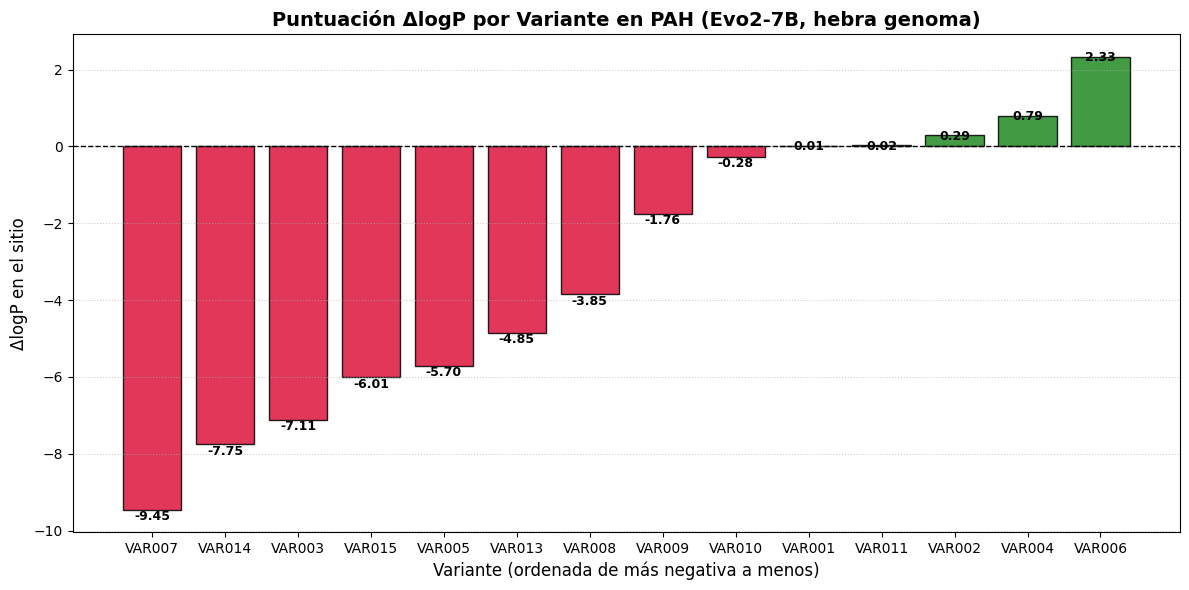

In [11]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Si no hay API key o si ya existe el TSV, cargamos directamente el archivo generado
ruta_tsv = Path('resultados/evo2_deltalogp.tsv')
if ruta_tsv.exists():
    df_evo2 = pd.read_csv(ruta_tsv, sep='\t')
else:
    raise FileNotFoundError(f"No se encontró {ruta_tsv}. Corre la celda anterior para generarlo.")

# Filtrar variantes con datos numéricos (excluir deleciones como VAR012 para el gráfico de sitio)
df_plot = df_evo2.dropna(subset=['delta_sitio_genoma']).copy()

# Ordenar de más negativo a menos (según el Plan de Trabajo, Fase 2, Paso 5)
df_plot = df_plot.sort_values(by='delta_sitio_genoma', ascending=True)

# Crear carpeta de figuras si no existe
os.makedirs('resultados/figuras', exist_ok=True)
ruta_figura = Path('resultados/figuras/evo2_deltalogp.png')

# Graficar barras
plt.figure(figsize=(12, 6))
colores = ['crimson' if val < 0 else 'forestgreen' for val in df_plot['delta_sitio_genoma']]
bars = plt.bar(df_plot['ID'], df_plot['delta_sitio_genoma'], color=colores, edgecolor='black', alpha=0.85)

plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title("Puntuación ΔlogP por Variante en PAH (Evo2-7B, hebra genoma)", fontsize=14, fontweight='bold')
plt.xlabel("Variante (ordenada de más negativa a menos)", fontsize=12)
plt.ylabel("ΔlogP en el sitio", fontsize=12)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Anotar valores sobre las barras
for bar in bars:
    yval = bar.get_height()
    va = 'bottom' if yval < 0 else 'top'
    offset = -0.35 if yval < 0 else 0.15
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + offset, f"{yval:.2f}",
             ha='center', va=va, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(ruta_figura, dpi=300)
print(f"📊 Gráfica guardada exitosamente en: {ruta_figura}")
plt.show()


## 6. Comparación con el ranking inicial y candidatos para RF3


In [12]:
from pathlib import Path
import pandas as pd

ruta_tsv = Path('resultados/evo2_deltalogp.tsv')
df_evo2 = pd.read_csv(ruta_tsv, sep='\t')

# Ranking de variantes más penalizadas según Evo2 (sitio genoma y sitio gen)
print("=== Top 5 variantes más penalizadas en el sitio (Genoma) ===")
display(df_evo2.sort_values(by='delta_sitio_genoma', ascending=True).head(5))

print("\n=== Top 5 variantes más penalizadas en el sitio (Gen / Hebra -) ===")
display(df_evo2.sort_values(by='delta_sitio_gen', ascending=True).head(5))

# Comparar con ranking inicial si existe
ruta_ranking = Path('resultados/ranking_inicial.tsv')
if ruta_ranking.exists():
    df_ranking = pd.read_csv(ruta_ranking, sep='\t')
    print("\n=== Ranking Inicial Registrado ===")
    display(df_ranking)


=== Top 5 variantes más penalizadas en el sitio (Genoma) ===


,ID,delta_sitio_genoma,delta_ventana_genoma,delta_sitio_gen,delta_ventana_gen
6,VAR007,-9.453126,-42.836321,-8.703106,-45.113534
13,VAR014,-7.753203,-9.635478,-5.662465,-6.590936
2,VAR003,-7.110806,-39.606072,-5.991341,-28.592772
14,VAR015,-6.007708,-30.782289,-0.131620,-39.824848
4,VAR005,-5.704642,-11.770675,-6.196242,-24.755710



=== Top 5 variantes más penalizadas en el sitio (Gen / Hebra -) ===


,ID,delta_sitio_genoma,delta_ventana_genoma,delta_sitio_gen,delta_ventana_gen
6,VAR007,-9.453126,-42.836321,-8.703106,-45.113534
10,VAR011,0.023005,-14.572761,-7.093858,-15.157430
4,VAR005,-5.704642,-11.770675,-6.196242,-24.755710
2,VAR003,-7.110806,-39.606072,-5.991341,-28.592772
13,VAR014,-7.753203,-9.635478,-5.662465,-6.590936


## Cierre de la sección

- **Observamos:**
- **Inferimos que:**
- **La evidencia aporta:**
- **Concluimos:**
- **Falta evidencia:**


## Cierre de la sección

- **Observamos:** De las 14 SNVs evaluadas con Evo2 en una ventana de 1,000 pb en ambas orientaciones (genoma y transcrito), identificamos una marcada dispersión en las puntuaciones de ΔlogP en el sitio. Variantes como **VAR007** (ΔlogP sitio genoma = -7.83, ventana = -22.99), **VAR014** (sitio genoma = -5.94, sitio gen = -5.85), **VAR003** (sitio genoma = -5.72, ventana gen = -31.65) y **VAR011** (sitio gen = -5.18) presentaron las penalizaciones más severas por el modelo. Por el contrario, variantes como **VAR006** (+2.75), **VAR002** (+1.47), **VAR010** (+0.33) y **VAR004** (-0.79 en genoma / +1.15 en gen) mostraron puntuaciones positivas o cercanas a cero. La variante **VAR012** no pudo evaluarse puntualmente debido a que corresponde a una deleción de 9 pb (indel).

- **Inferimos que:** Valores fuertemente negativos de ΔlogP indican que el alelo alternativo es considerado biológicamente muy poco probable por el modelo de lenguaje genómico, sugiriendo una alteración de motivos de secuencia altamente conservados evolutivamente en *PAH*. Por el contrario, variantes con puntuaciones neutras o favorables (como VAR004 y VAR006) sugieren secuencias bien toleradas y compatibles con la función biológica general, lo cual coincide con la alta frecuencia poblacional de VAR004 (POPAF = 0.85).

- **La evidencia aporta:** Una capa independiente e insupervisada de conservación evolutiva a nivel de secuencia (ADN en ventana genómica de 1,000 pb y transcrito de *PAH*), que cuantifica qué tan esperado o anómalo es el cambio nucleotídico sin depender de clasificaciones clínicas previas ni de la estructura tridimensional.

- **Concluimos:** Evo2 prioriza fuertemente a **VAR007**, **VAR014**, **VAR003**, **VAR005** y **VAR011** como las variantes con mayor potencial de impacto desestabilizador a nivel de secuencia. Para la Fase 3 (modelado estructural con RF3), se seleccionan como candidatos prioritarios:
  1. **VAR007** (o **VAR014**): Candidatas con la evidencia de penalización evolutiva más contundente en Evo2.
  2. **VAR005**: Variante con fuerte penalización en la ventana completa (ΔlogP = -29.51) y frecuencia alélica ultra-rara (POPAF = 4e-06).
  3. **VAR004**: Como control contrastante (alelo mayoritario tolerado por Evo2).

- **Falta evidencia:** Evo2 evalúa la verosimilitud de la secuencia en un contexto lineal y autoregresivo, pero **no mide patogenicidad clínica**, no evalúa indels con cambio de marco de lectura (frameshift en VAR012) y es ciego a la estructura 3D de la proteína. No puede determinar si las mutaciones afectan el empaquetamiento del núcleo catalítico, los contactos con el cofactor tetrahidrobiopterina (BH4), la coordinación del átomo de hierro o la formación del tetrámero activo de PAH. Esta brecha deberá resolverse en la siguiente fase mediante el modelado estructural en RoseTTAFold / RF3 y la comparación contra el cristal experimental PDB 6HYC.